In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import gridspec
import matplotlib.ticker as ticker
import matplotlib.lines as mlines
from matplotlib.colors import BoundaryNorm, ListedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.patches import Rectangle
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter,AutoMinorLocator)

In [2]:
# This script reproduces Fig. 1A and 1B.
#
# Fig. 1A shows the daily evolution of standardized anomalies over
# southwestern North America during 1–31 March 2026 for four variables.
#   - Daily maximum temperature (Tx)
#   - 500 hPa geopotential height (Z500)
#   - Surface soil moisture (SWVL1)
#   - 1000 hPa relative humidity (RH)
# The panel also compares daily maximum temperatures (°C) in March 2026
# with those for the same calendar dates in 1950–2025.
#
# Fig. 1B shows standardized daily amplitudes for zonal wavenumbers 4
# and 5. Hatching indicates periods of quasi-resonant amplification (QRA) identified.

# Define period
strt_yy = "2026"
end_yy = "2026"

strt_mm = "03" 
strt_dd = "01" 
end_mm = "03"  
end_dd = "31"  

start = strt_yy + "-" + strt_mm + "-" + strt_dd 
end   = end_yy + "-" + end_mm + "-" + end_dd   
timerange = pd.date_range(start=start,end=end, freq='D').strftime("%m-%d").tolist()
xlim = len(timerange)  

# Plot settings 
x_pos = [0,7,14,22,30]   
x_pos_temp = [x+0.5 for x in x_pos]
x = [x + 0.5 for x in range(0, xlim)]
tlabels = [timerange[k] for k in x_pos]
size = 16
labelsize = 14
fontsize = 12

# Colors for Fig. 1A
col_tx   = "red"
col_z500  = "blue"
col_swvl1 = "orange"
col_r1000 = "green"

# Colors for Fig. 1B
pal_greens = sns.color_palette("Greens")
hex_greens = pal_greens.as_hex()[:]
pal_greys = sns.color_palette("Greys")
hex_greys = pal_greys.as_hex()[:]
pal_oranges = sns.color_palette("Oranges")
hex_oranges = pal_oranges.as_hex()[:]
pal_reds = sns.color_palette("Reds")
hex_reds = pal_reds.as_hex()[:]
col_ampm = [hex_greys[2], hex_greys[1], hex_greys[0], hex_greens[0], hex_greens[1], hex_oranges[1], hex_oranges[2], hex_oranges[3], hex_reds[4]]
cmap = ListedColormap(col_ampm)
bounds = [-1.5, -1.0, -0.5, 0, 0.5, 1, 1.5, 2, 2.5, 3] 
norm = BoundaryNorm(bounds, ncolors=len(col_ampm))

In [3]:
# Define homepath and read each CSV files
homepath = "/pscratch/sd/x/xueke/Github/"
df_tx_sigma_2026 = pd.read_csv(homepath + "data/tx_sigma_2026.csv", index_col='Date')
df_tx_abs_1950_2026 = pd.read_csv(homepath + "data/tx_absolute_1950_2026.csv", index_col='Year')
df_z500_sigma_2026 = pd.read_csv(homepath + "data/z500_sigma_2026.csv", index_col='Date')
df_swvl1_sigma_2026 = pd.read_csv(homepath + "data/swvl1_sigma_2026.csv", index_col='Date')
df_r1000_sigma_2026 = pd.read_csv(homepath + "data/r1000_sigma_2026.csv", index_col='Date')
df_ampm_2026 = pd.read_csv(homepath + "data/ampm_2026.csv", index_col='Date')

tx_sigma_2026 = df_tx_sigma_2026['tx'].values
z500_sigma_2026 = df_z500_sigma_2026['z500'].values
swvl1_sigma_2026 = df_swvl1_sigma_2026['swvl1'].values
r1000_sigma_2026 = df_r1000_sigma_2026['r1000'].values
ampm_wnr4 = df_ampm_2026['ampm_wnr4'].values
ampm_wnr5 = df_ampm_2026['ampm_wnr5'].values
df_wnr4 = pd.DataFrame(ampm_wnr4, index=np.arange(xlim))
df_wnr5 = pd.DataFrame(ampm_wnr5, index=np.arange(xlim))
df_wnr4.columns = ["4"]
df_wnr5.columns = ["5"]
df_wnr4_transposed = df_wnr4.transpose()
df_wnr5_transposed = df_wnr5.transpose()
df_transposed = pd.concat([df_wnr5_transposed, df_wnr4_transposed])

# Plot

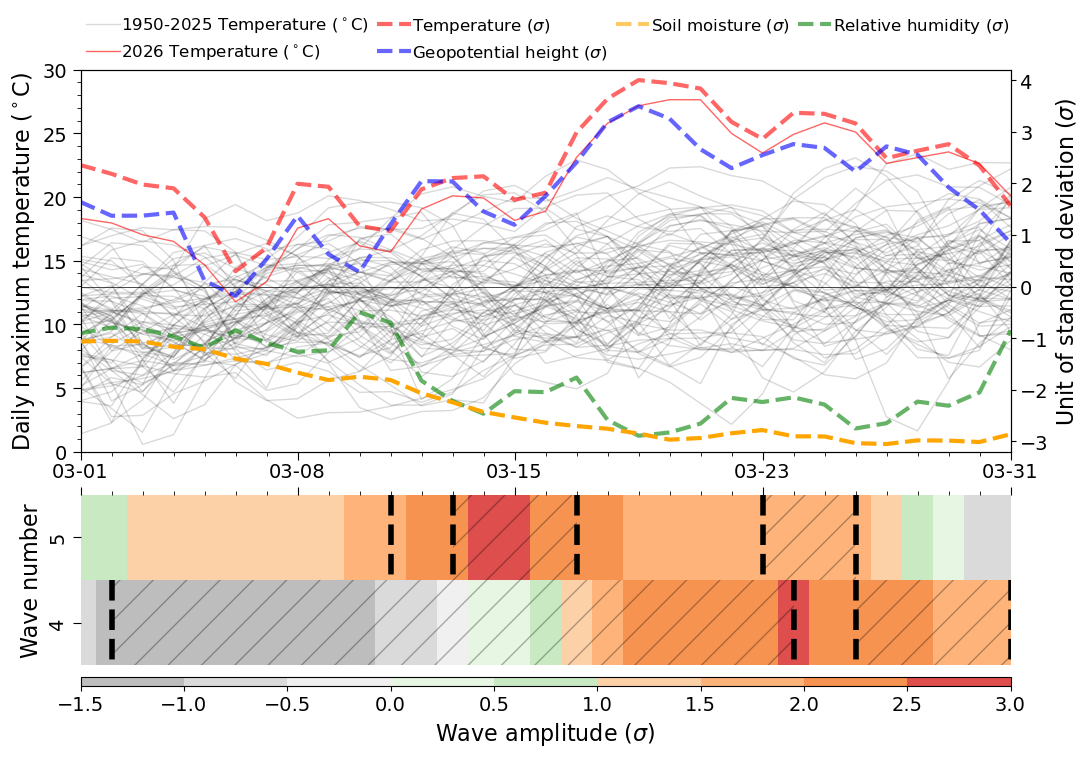

In [4]:
fig = plt.figure(figsize=(12,8))
gs = gridspec.GridSpec(2, 1, height_ratios=[2,1]) 
ax1 = plt.subplot(gs[0])                                # ax1: display Tx absolute value including March 2026 and March of 1950-2025 
ax2 = ax1.twinx()                                       # ax2: display standardized anomalies (σ) for Tx, Z500, SWVL1, and RH
ax3 = plt.subplot(gs[1])                                # ax3: display standardized daily amplitudes (σ) QRA-detected waves 4 and 5

################ ax1 ################
ax1.plot(x, df_tx_abs_1950_2026.loc[1950:2025].T, color="black", linewidth = 1, alpha=0.15)
ax1.plot(x, df_tx_abs_1950_2026.loc[2026], color=col_tx, linewidth = 1, alpha=0.6) 

ax1.set_ylabel('Daily maximum temperature ($^\circ$C)', size=size, multialignment='center')  
ax1.tick_params(labelbottom=False)  
ax1.tick_params('y',labelsize=labelsize)
ax1.tick_params(which='major', length=6) 
ax1.tick_params(which='minor', length=3)
minor_locator = AutoMinorLocator(7)
ax1.xaxis.set_minor_locator(minor_locator)
ax1.yaxis.set_minor_locator(ticker.MultipleLocator(1))
ax1.set_ylim(0, 30)
ax1.set_xlim(0.5, xlim-0.5) 

# Manually draw the legend lines
tx_dashed_line = mlines.Line2D([], [], color=col_tx, linewidth = 3, linestyle='dashed', alpha=0.6, label='Temperature ($\sigma$)')
z500_dashed_line = mlines.Line2D([], [], color=col_z500, linewidth = 3, linestyle='dashed',alpha=0.6,  label='Geopotential height ($\sigma$)') 
swvl1_dashed_line = mlines.Line2D([], [], color=col_swvl1, linewidth = 3, linestyle='dashed',alpha=0.6,  label='Soil moisture ($\sigma$)')
r1000_dashed_line = mlines.Line2D([], [], color=col_r1000, linewidth = 3, linestyle='dashed',alpha=0.6,  label='Relative humidity ($\sigma$)')
black_line = mlines.Line2D([], [], color='black', alpha=0.15, linewidth = 1, label='1950-2025 Temperature ($^\circ$C)')
tx_line = mlines.Line2D([], [], color=col_tx, alpha=0.6, linewidth = 1, label='2026 Temperature ($^\circ$C)')  
ax1.legend(bbox_to_anchor=(-0.01, 0.98), loc="lower left", ncol=4, fontsize = fontsize, frameon=False, 
           handles=[black_line, tx_line, tx_dashed_line, z500_dashed_line, swvl1_dashed_line, r1000_dashed_line], 
           handletextpad=0.1, columnspacing=0.5)

################ ax2 ################     
ax2.plot(x, tx_sigma_2026, color=col_tx, linewidth = 3, linestyle='dashed', alpha=0.6, zorder=1)
ax2.plot(x, z500_sigma_2026, color=col_z500, linewidth = 3, linestyle='dashed', alpha=0.6, zorder=2) 
ax2.plot(x, swvl1_sigma_2026, color=col_swvl1, linewidth = 3, linestyle='dashed', zorder=4)
ax2.plot(x, r1000_sigma_2026, color=col_r1000, linewidth = 3, linestyle='dashed', alpha=0.6, zorder=3)

ax2.axhline(y=0, color='black', linewidth = 0.5, linestyle='-')
ax2.set_xticks(x_pos_temp)
ax2.set_ylabel('Unit of standard deviation ($\sigma$)', size=size)  
ax2.tick_params('y',labelsize=labelsize)
minor_locator = AutoMinorLocator(7)
ax2.xaxis.set_minor_locator(minor_locator)
ax2.yaxis.set_major_locator(ticker.MultipleLocator(1))
ax2.set_xlim(0.5, xlim-0.5)
ax2.set_ylim(-3.2, 4.2)

################ ax3 ################   
p = sns.heatmap(df_transposed, ax=ax3, cmap=cmap, norm=norm, vmin=-2.0, vmax=2.0, alpha=0.8, cbar=False)
p.set_ylabel('Wave number',size=size)
p.yaxis.set_tick_params(labelsize=labelsize)

divider3 = make_axes_locatable(ax3)
cax3 = divider3.append_axes("bottom", size="5%", pad=0.12)
outpathc = p.get_children()[0] 
c = plt.colorbar(mappable=outpathc, cax=cax3, orientation='horizontal') 
c.set_label('Wave amplitude ($\sigma$)', size=size)
c.ax.tick_params(labelsize=labelsize)

# Wave 4 
ax3.vlines([1.5, 23.5, 25.5, 30.5], ymin=1, ymax=2, color='black', linewidth=4, linestyle='dashed')
for x0, x1 in [(1.5, 23.5), (25.5, 30.5)]:
    ax3.add_patch(Rectangle((x0, 1), x1 - x0, 1, facecolor='none', edgecolor=(0, 0, 0, 0.3), linewidth=0, hatch='/'))

# Wave 5
ax3.vlines([10.5, 12.5, 16.5, 22.5, 25.5], ymin=0, ymax=1, color='black', linewidth=4, linestyle='dashed')
for x0, x1 in [(12.5, 16.5), (22.5, 25.5)]:
    ax3.add_patch(Rectangle((x0, 0), x1 - x0, 1, facecolor='none', edgecolor=(0, 0, 0, 0.3), linewidth=0, hatch='/'))
    
ax3.xaxis.set_ticks_position('top')
ax3.set_xlim(0.5, xlim-0.5)
ax3.set_xticks(x_pos_temp)
ax3.set_xticklabels(tlabels, ha='center')
ax3.tick_params('x',labelsize=labelsize)
ax3.tick_params(which='major', length=6) #width=2
ax3.tick_params(which='minor', length=3)
minor_locator = AutoMinorLocator(7)
ax3.xaxis.set_minor_locator(minor_locator)

plt.subplots_adjust(hspace=0.15) 

# Save plot
plt.savefig(homepath+ 'figures/Fig_1ab.pdf', format='pdf', dpi=600, bbox_inches='tight') 